In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [2]:
def calculate_applicability_domain(df_train, df_candidates, feature_cols, dopant_cols):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(df_train[feature_cols])
    X_candidates_scaled = scaler.transform(df_candidates[feature_cols])

    nn = NearestNeighbors(n_neighbors=1, metric='euclidean')
    nn.fit(X_train_scaled)

    distances, indices = nn.kneighbors(X_candidates_scaled)
    df_candidates['Dist_to_Nearest_Train_Sample'] = distances.flatten()

    comp_scaler = StandardScaler()
    C_train_scaled = comp_scaler.fit_transform(df_train[dopant_cols])
    C_candidates_scaled = comp_scaler.transform(df_candidates[dopant_cols])

    nn_comp = NearestNeighbors(radius=0.5, metric='euclidean')
    nn_comp.fit(C_train_scaled)

    counts = []
    for i, candidate in enumerate(C_candidates_scaled):
        neighbors = nn_comp.radius_neighbors([candidate], return_distance=False)
        counts.append(len(neighbors[0]))

    df_candidates['Num_Similar_Train_Records'] = counts

    return df_candidates

In [3]:
OPT_VARS = [
    "f_avg_core_width_nm",
    "f_Ms_emu_g_MNP",
    "f_Hc_Oe",
    "f_H_Oe",
    "f_FCY_kHz",
    "Zn_comp", "Co_comp", "Ca_comp", "Cu_comp", "Ni_comp","Mg_comp","Mn_comp"
]

DOPANT_COLS = ["Zn_comp", "Co_comp", "Ca_comp", "Cu_comp", "Ni_comp", "Fe_comp","Mg_comp","Mn_comp"]

df1 = pd.read_excel("Final.xlsx")

cutoff_threshold = df1['f_SAR_W_g'].quantile(0.95)

filtered_df = df1[df1['f_SAR_W_g'] <= cutoff_threshold]

df1 = filtered_df
df2 = pd.read_excel("top_candidates_tabpfn_retro.xlsx")

df1_cleaned = df1.dropna(subset=list(set(OPT_VARS + DOPANT_COLS)))
df2_cleaned = df2.dropna(subset=list(set(OPT_VARS + DOPANT_COLS)))

updated_candidates_df = calculate_applicability_domain(
    df_train=df1_cleaned,
    df_candidates=df2_cleaned,
    feature_cols=OPT_VARS,
    dopant_cols=DOPANT_COLS
)

display_columns = ['Active_Dopants', 'Predicted_SAR_W_g', 'Dist_to_Nearest_Train_Sample', 'Num_Similar_Train_Records']
updated_candidates_df.to_excel("SIMILARITY_RETRO.xlsx")
print(updated_candidates_df[display_columns].head(10))

            Active_Dopants  Predicted_SAR_W_g  Dist_to_Nearest_Train_Sample  \
0  Ni_comp+Mg_comp+Mn_comp         117.441408                      3.250623   
1          Mg_comp+Mn_comp         113.630668                      3.043951   
2          Co_comp+Mn_comp         107.802010                      2.539751   
3          Co_comp+Ni_comp         100.028556                      2.720689   
4          Zn_comp+Ni_comp          99.236082                      3.306915   
5          Zn_comp+Co_comp          98.007187                      2.728785   
6          Cu_comp+Mg_comp          96.789373                      3.781103   
7  Ni_comp+Mg_comp+Mn_comp          96.195301                      3.106500   
8          Mg_comp+Mn_comp          96.134365                      3.071303   
9          Mg_comp+Mn_comp          95.919999                      3.249927   

   Num_Similar_Train_Records  
0                          0  
1                          0  
2                          0  
3     

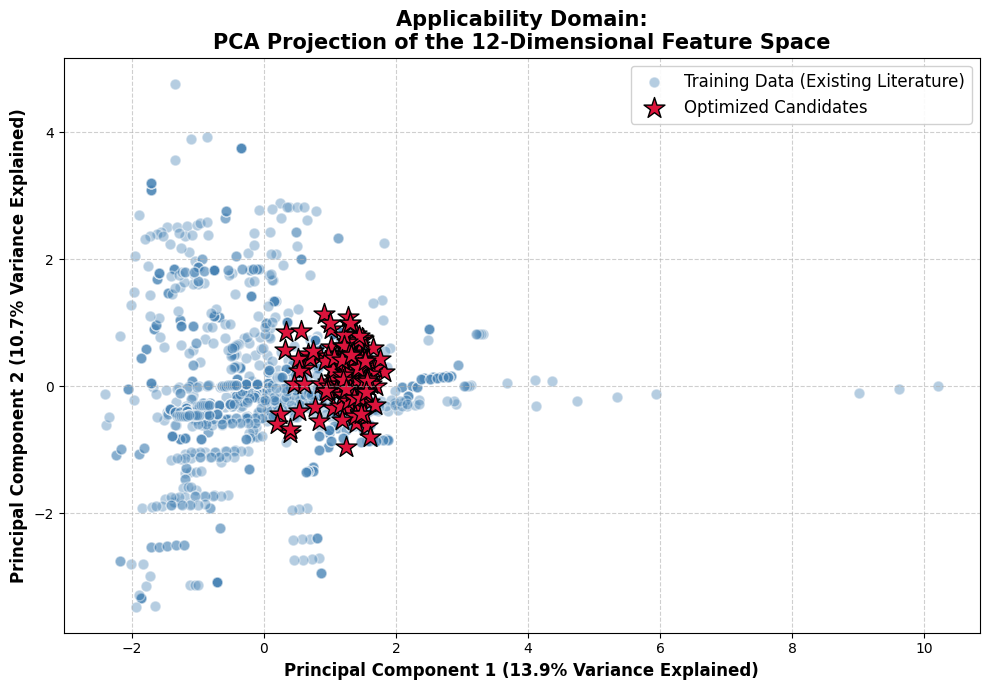

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(df1_cleaned[OPT_VARS])
X_candidates_scaled = scaler.transform(df2_cleaned[OPT_VARS])

pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_candidates_pca = pca.transform(X_candidates_scaled)

plt.figure(figsize=(10, 7))

plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], alpha=0.4, c='steelblue',
            label='Training Data (Existing Literature)', edgecolors='w', s=60)

plt.scatter(X_candidates_pca[:, 0], X_candidates_pca[:, 1], c='crimson',
            marker='*', s=250, label='Optimized Candidates', edgecolors='black', linewidths=1)

plt.title('Applicability Domain:\nPCA Projection of the 12-Dimensional Feature Space',
          fontsize=15, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance Explained)',
           fontsize=12, fontweight='bold')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance Explained)',
           fontsize=12, fontweight='bold')
plt.legend(loc='best', fontsize=12, framealpha=0.9)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("Similarity_plot.png")
plt.show()